In [2]:
from google.colab import files

uploaded = files.upload()

Saving train_values.csv to train_values (1).csv
Saving train_labels.csv to train_labels (1).csv


Load the datasets

In [3]:
import pandas as pd

train_values = pd.read_csv("train_values.csv")
train_labels = pd.read_csv("train_labels.csv")

print("Train values shape:", train_values.shape)
print("Train labels shape:", train_labels.shape)

Train values shape: (260601, 39)
Train labels shape: (260601, 2)


Merge

In [4]:
df = train_values.merge(train_labels, on="building_id")

print("Merged dataset shape:", df.shape)

Merged dataset shape: (260601, 40)


See all columns

In [5]:
print("Columns in our dataset:\n")
for i, col in enumerate(df.columns, 1):
    print(i, ":", col)

Columns in our dataset:

1 : building_id
2 : geo_level_1_id
3 : geo_level_2_id
4 : geo_level_3_id
5 : count_floors_pre_eq
6 : age
7 : area_percentage
8 : height_percentage
9 : land_surface_condition
10 : foundation_type
11 : roof_type
12 : ground_floor_type
13 : other_floor_type
14 : position
15 : plan_configuration
16 : has_superstructure_adobe_mud
17 : has_superstructure_mud_mortar_stone
18 : has_superstructure_stone_flag
19 : has_superstructure_cement_mortar_stone
20 : has_superstructure_mud_mortar_brick
21 : has_superstructure_cement_mortar_brick
22 : has_superstructure_timber
23 : has_superstructure_bamboo
24 : has_superstructure_rc_non_engineered
25 : has_superstructure_rc_engineered
26 : has_superstructure_other
27 : legal_ownership_status
28 : count_families
29 : has_secondary_use
30 : has_secondary_use_agriculture
31 : has_secondary_use_hotel
32 : has_secondary_use_rental
33 : has_secondary_use_institution
34 : has_secondary_use_school
35 : has_secondary_use_industry
36 : has_

separate X and y

In [6]:
X = df.drop(columns=["damage_grade", "building_id"])
y = df["damage_grade"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (260601, 38)
y shape: (260601,)


Check data types

In [7]:
print("Data types of all features:\n")
print(X.dtypes)

Data types of all features:

geo_level_1_id                             int64
geo_level_2_id                             int64
geo_level_3_id                             int64
count_floors_pre_eq                        int64
age                                        int64
area_percentage                            int64
height_percentage                          int64
land_surface_condition                    object
foundation_type                           object
roof_type                                 object
ground_floor_type                         object
other_floor_type                          object
position                                  object
plan_configuration                        object
has_superstructure_adobe_mud               int64
has_superstructure_mud_mortar_stone        int64
has_superstructure_stone_flag              int64
has_superstructure_cement_mortar_stone     int64
has_superstructure_mud_mortar_brick        int64
has_superstructure_cement_mortar_brick  

separate categorical and numerical features

In [8]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumber of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numerical_features)

print("\nNumber of numerical features:", len(numerical_features))

Categorical features:
['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

Number of categorical features: 8

Numerical features:
['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post

check missing valuesDamage-grade distribution

In [9]:
missing_values = X.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


In [10]:
print("Damage Grade Distribution:")
print(y.value_counts().sort_index())

print("\nPercentage Distribution:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Damage Grade Distribution:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64

Percentage Distribution:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64


Split the data into training and validation sets

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)

print("\nTraining labels:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nValidation labels:")
print(y_val.value_counts(normalize=True).sort_index().round(4))

Training set: (208480, 38)
Validation set: (52121, 38)

Training labels:
damage_grade
1    0.0964
2    0.5689
3    0.3347
Name: proportion, dtype: float64

Validation labels:
damage_grade
1    0.0964
2    0.5689
3    0.3347
Name: proportion, dtype: float64


Preprocessing

In [12]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


transform the data

In [13]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Processed training data shape:", X_train_processed.shape)
print("Processed validation data shape:", X_val_processed.shape)

Processed training data shape: (208480, 68)
Processed validation data shape: (52121, 68)


Select the 20 best features for KNN

In [14]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=20)

X_train_knn = selector.fit_transform(X_train_processed, y_train)
X_val_knn = selector.transform(X_val_processed)

print("KNN training shape:", X_train_knn.shape)
print("KNN validation shape:", X_val_knn.shape)

KNN training shape: (208480, 20)
KNN validation shape: (52121, 20)


Train KNN

In [15]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=7,
    n_jobs=-1
)

knn.fit(X_train_knn, y_train)

print("KNN training completed.")

KNN training completed.


KNN prediction + evaluation

In [16]:

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Use a smaller validation sample for KNN evaluation
X_val_knn_small = X_val_knn[:10000]
y_val_knn_small = y_val.iloc[:10000]

print("KNN evaluation samples:", len(y_val_knn_small))

y_pred_knn = knn.predict(X_val_knn_small)

knn_accuracy = accuracy_score(y_val_knn_small, y_pred_knn)
knn_f1 = f1_score(y_val_knn_small, y_pred_knn, average="micro")

print("KNN Accuracy:", round(knn_accuracy, 4))
print("KNN Micro-F1:", round(knn_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val_knn_small, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_knn_small, y_pred_knn))

KNN evaluation samples: 10000
KNN Accuracy: 0.6446
KNN Micro-F1: 0.6446

Classification Report:
              precision    recall  f1-score   support

           1       0.49      0.40      0.44      1014
           2       0.67      0.76      0.71      5682
           3       0.64      0.52      0.57      3304

    accuracy                           0.64     10000
   macro avg       0.60      0.56      0.57     10000
weighted avg       0.64      0.64      0.64     10000


Confusion Matrix:
[[ 401  590   23]
 [ 388 4341  953]
 [  31 1569 1704]]


Neural Network

In [17]:
from sklearn.neural_network import MLPClassifier

nn_model = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation="logistic",
    solver="adam",
    alpha=0.0001,
    batch_size=1000,
    learning_rate_init=0.002,
    max_iter=30,
    random_state=42,
    verbose=True
)

nn_model.fit(X_train_processed, y_train)

print("Neural Network training completed.")

Iteration 1, loss = 0.90780377
Iteration 2, loss = 0.80153856
Iteration 3, loss = 0.79005242
Iteration 4, loss = 0.78377102
Iteration 5, loss = 0.77875369
Iteration 6, loss = 0.77456241
Iteration 7, loss = 0.77131409
Iteration 8, loss = 0.76846885
Iteration 9, loss = 0.76619927
Iteration 10, loss = 0.76446920
Iteration 11, loss = 0.76305475
Iteration 12, loss = 0.76201838
Iteration 13, loss = 0.76105248
Iteration 14, loss = 0.76047787
Iteration 15, loss = 0.75985047
Iteration 16, loss = 0.75916550
Iteration 17, loss = 0.75863813
Iteration 18, loss = 0.75803621
Iteration 19, loss = 0.75769733
Iteration 20, loss = 0.75718022
Iteration 21, loss = 0.75669689
Iteration 22, loss = 0.75630126
Iteration 23, loss = 0.75591725
Iteration 24, loss = 0.75532579
Iteration 25, loss = 0.75490955
Iteration 26, loss = 0.75451113
Iteration 27, loss = 0.75402804
Iteration 28, loss = 0.75356805
Iteration 29, loss = 0.75313095
Iteration 30, loss = 0.75270826
Neural Network training completed.


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Neural Network prediction

In [18]:
y_pred_nn = nn_model.predict(X_val_processed)

nn_accuracy = accuracy_score(y_val, y_pred_nn)
nn_f1 = f1_score(y_val, y_pred_nn, average="micro")

print("Neural Network Accuracy:", round(nn_accuracy, 4))
print("Neural Network Micro-F1:", round(nn_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_nn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_nn))

Neural Network Accuracy: 0.6304
Neural Network Micro-F1: 0.6304

Classification Report:
              precision    recall  f1-score   support

           1       0.60      0.35      0.45      5025
           2       0.64      0.81      0.72     29652
           3       0.60      0.40      0.48     17444

    accuracy                           0.63     52121
   macro avg       0.61      0.52      0.55     52121
weighted avg       0.62      0.63      0.61     52121


Confusion Matrix:
[[ 1781  2994   250]
 [ 1098 24099  4455]
 [   75 10390  6979]]


RANDOM FOREST

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed.")

Random Forest training completed.


Random Forest prediction

In [20]:
y_pred_rf = rf_model.predict(X_val_processed)

rf_accuracy = accuracy_score(y_val, y_pred_rf)
rf_f1 = f1_score(y_val, y_pred_rf, average="micro")

print("Random Forest Accuracy:", round(rf_accuracy, 4))
print("Random Forest Micro-F1:", round(rf_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_rf))

Random Forest Accuracy: 0.7157
Random Forest Micro-F1: 0.7157

Classification Report:
              precision    recall  f1-score   support

           1       0.64      0.48      0.55      5025
           2       0.72      0.82      0.77     29652
           3       0.72      0.60      0.65     17444

    accuracy                           0.72     52121
   macro avg       0.69      0.63      0.66     52121
weighted avg       0.71      0.72      0.71     52121


Confusion Matrix:
[[ 2416  2510    99]
 [ 1227 24404  4021]
 [  128  6835 10481]]


COMPARE ALL 3 MODEL

In [21]:
results = pd.DataFrame({
    "Model": [
        "KNN",
        "Neural Network",
        "Random Forest"
    ],
    "Accuracy": [
        knn_accuracy,
        nn_accuracy,
        rf_accuracy
    ],
    "Micro-F1": [
        knn_f1,
        nn_f1,
        rf_f1
    ]
})

results

,Model,Accuracy,Micro-F1
0,KNN,0.644600,0.644600
1,Neural Network,0.630437,0.630437
2,Random Forest,0.715662,0.715662


CONFUSION MATRICES

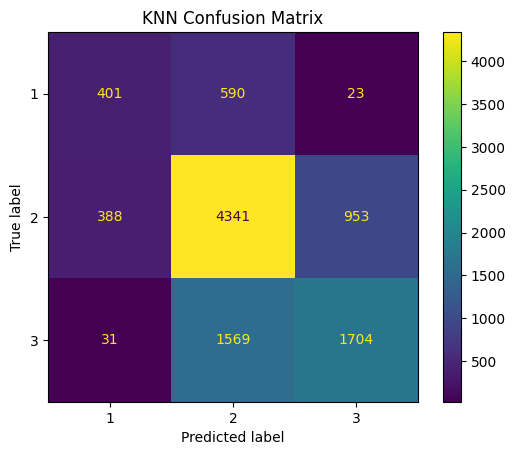

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val_knn_small,
    y_pred_knn,
    display_labels=[1, 2, 3]
)

plt.title("KNN Confusion Matrix")
plt.show()

Neural Network confusion matrix

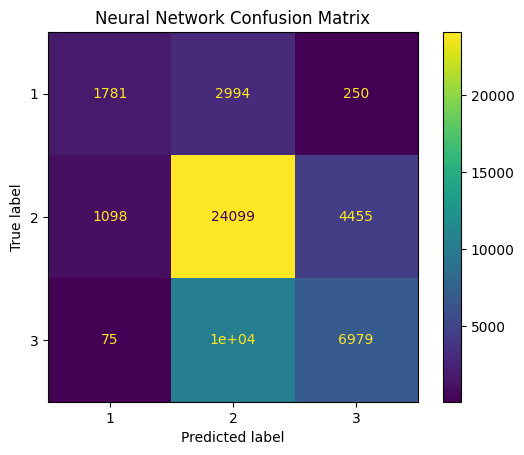

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_nn,
    display_labels=[1, 2, 3]
)

plt.title("Neural Network Confusion Matrix")
plt.show()

Random Forest confusion matrix

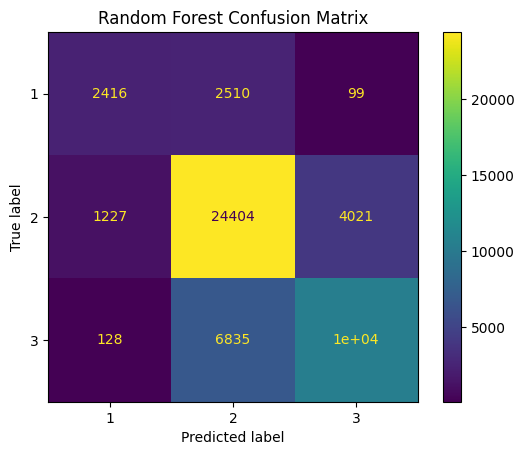

In [24]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    display_labels=[1, 2, 3]
)

plt.title("Random Forest Confusion Matrix")
plt.show()

MODEL COMPARISON GRAPH

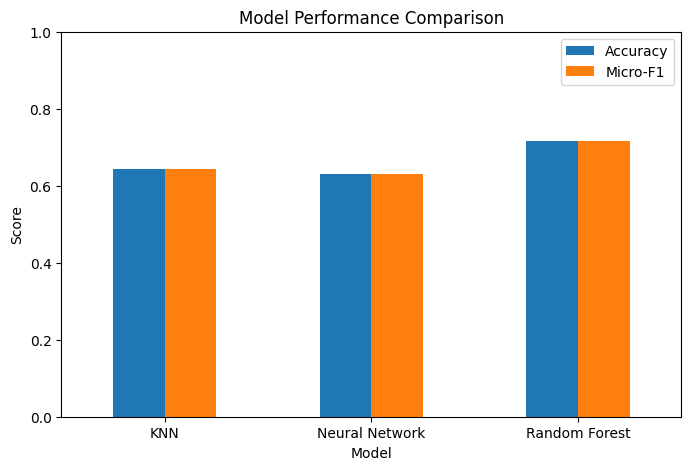

In [25]:
results.set_index("Model")[["Accuracy", "Micro-F1"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

RANDOM FOREST FEATURE IMPORTANCE

In [26]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
2,num__geo_level_3_id,0.152891
1,num__geo_level_2_id,0.134381
0,num__geo_level_1_id,0.133391
4,num__age,0.121340
5,num__area_percentage,0.113307
6,num__height_percentage,0.056311
18,num__count_families,0.025126
3,num__count_floors_pre_eq,0.016402
35,cat__foundation_type_r,0.014867
8,num__has_superstructure_mud_mortar_stone,0.013175


Plot top 20 features

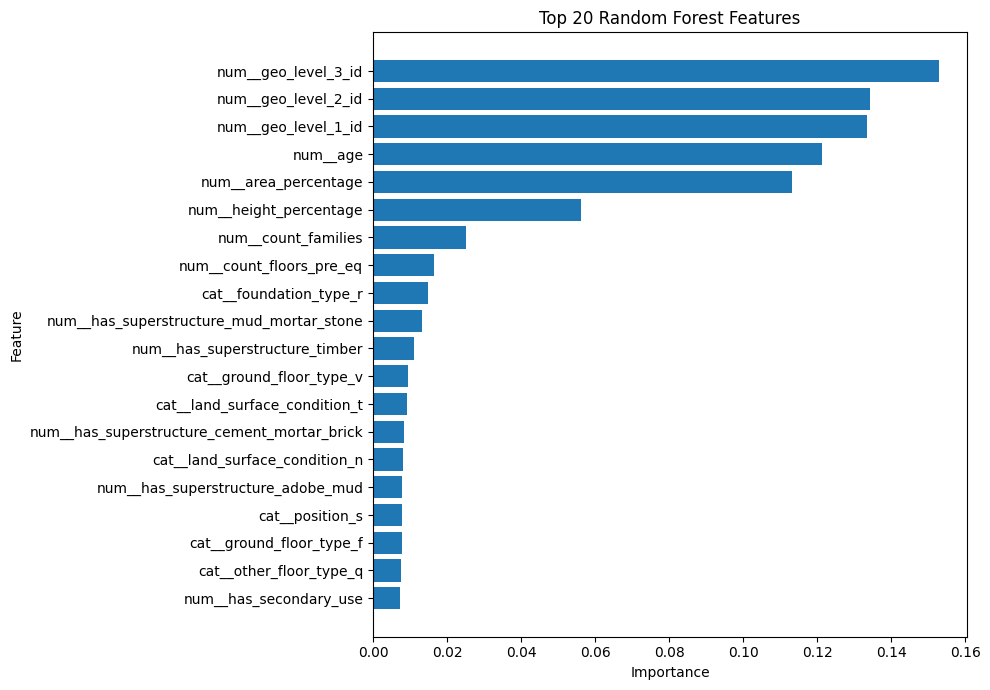

In [27]:
top_features = feature_importance.head(20).sort_values("Importance")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Features")

plt.tight_layout()
plt.show()

USE test_values.csv

In [28]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

test_values = pd.read_csv("test_values.csv")

print("Test data shape:", test_values.shape)

Saving test_values.csv to test_values.csv
Test data shape: (86868, 39)


Separate Test Features

In [29]:
X_test = test_values.drop(columns=["building_id"])

print("Test features shape:", X_test.shape)

Test features shape: (86868, 38)


Preprocess Test Data

In [30]:
X_test_processed = preprocessor.transform(X_test)

print("Processed test data shape:", X_test_processed.shape)

Processed test data shape: (86868, 68)


Prepare Test Data for KNN

In [31]:
X_test_knn = selector.transform(X_test_processed)

print("KNN test data shape:", X_test_knn.shape)

KNN test data shape: (86868, 20)


KNN Test Predictions

In [32]:
test_pred_knn = knn.predict(X_test_knn)

print("KNN test predictions completed.")
print("First 20 predictions:")
print(test_pred_knn[:20])

KNN test predictions completed.
First 20 predictions:
[3 2 2 1 3 3 2 3 2 1 2 2 3 3 2 2 2 2 2 2]


Neural Network Test Predictions

In [33]:
test_pred_nn = nn_model.predict(X_test_processed)

print("Neural Network test predictions completed.")
print("First 20 predictions:")
print(test_pred_nn[:20])

Neural Network test predictions completed.
First 20 predictions:
[3 2 2 1 3 3 1 2 3 2 2 2 2 3 1 3 2 2 2 2]


Random Forest Test Predictions

In [34]:
test_pred_rf = rf_model.predict(X_test_processed)

print("Random Forest test predictions completed.")
print("First 20 predictions:")
print(test_pred_rf[:20])

Random Forest test predictions completed.
First 20 predictions:
[3 2 2 1 3 3 2 3 2 2 2 2 2 2 2 2 2 2 2 2]


Create Prediction DataFrames

In [35]:
knn_submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_pred_knn
})

nn_submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_pred_nn
})

rf_submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_pred_rf
})

print("All prediction files prepared.")

All prediction files prepared.


Check Predictions

In [36]:
print("KNN predictions:")
print(knn_submission.head())

print("\nNeural Network predictions:")
print(nn_submission.head())

print("\nRandom Forest predictions:")
print(rf_submission.head())

KNN predictions:
   building_id  damage_grade
0       300051             3
1        99355             2
2       890251             2
3       745817             1
4       421793             3

Neural Network predictions:
   building_id  damage_grade
0       300051             3
1        99355             2
2       890251             2
3       745817             1
4       421793             3

Random Forest predictions:
   building_id  damage_grade
0       300051             3
1        99355             2
2       890251             2
3       745817             1
4       421793             3


Check Damage Grade Distribution

In [37]:
print("KNN prediction distribution:")
print(knn_submission["damage_grade"].value_counts().sort_index())

print("\nNeural Network prediction distribution:")
print(nn_submission["damage_grade"].value_counts().sort_index())

print("\nRandom Forest prediction distribution:")
print(rf_submission["damage_grade"].value_counts().sort_index())

KNN prediction distribution:
damage_grade
1     6585
2    56738
3    23545
Name: count, dtype: int64

Neural Network prediction distribution:
damage_grade
1     4867
2    62367
3    19634
Name: count, dtype: int64

Random Forest prediction distribution:
damage_grade
1     6227
2    56395
3    24246
Name: count, dtype: int64


Save KNN Prediction File

In [38]:
knn_submission.to_csv(
    "knn_predictions.csv",
    index=False
)

print("KNN prediction file saved.")

KNN prediction file saved.


Save Neural Network Prediction File

In [39]:
nn_submission.to_csv(
    "neural_network_predictions.csv",
    index=False
)

print("Neural Network prediction file saved.")

Neural Network prediction file saved.


Save Random Forest Prediction File

In [40]:
rf_submission.to_csv(
    "random_forest_predictions.csv",
    index=False
)

print("Random Forest prediction file saved.")

Random Forest prediction file saved.


Download Random Forest Submission

In [41]:
final_submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_pred_rf
})

final_submission.to_csv(
    "nepal_earthquake_final_predictions.csv",
    index=False
)

print("Final prediction file created.")
print(final_submission.head())

Final prediction file created.
   building_id  damage_grade
0       300051             3
1        99355             2
2       890251             2
3       745817             1
4       421793             3


Download the Final File

In [42]:
from google.colab import files

files.download("nepal_earthquake_final_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model Comparison

In [43]:
results = pd.DataFrame({
    "Model": [
        "KNN",
        "Neural Network",
        "Random Forest"
    ],
    "Accuracy": [
        knn_accuracy,
        nn_accuracy,
        rf_accuracy
    ],
    "Micro-F1": [
        knn_f1,
        nn_f1,
        rf_f1
    ]
})

print(results)

            Model  Accuracy  Micro-F1
0             KNN  0.644600  0.644600
1  Neural Network  0.630437  0.630437
2   Random Forest  0.715662  0.715662


Rounded Results

In [44]:
results_rounded = results.copy()

results_rounded["Accuracy"] = results_rounded["Accuracy"].round(4)
results_rounded["Micro-F1"] = results_rounded["Micro-F1"].round(4)

results_rounded

,Model,Accuracy,Micro-F1
0,KNN,0.6446,0.6446
1,Neural Network,0.6304,0.6304
2,Random Forest,0.7157,0.7157


Comparison Graph

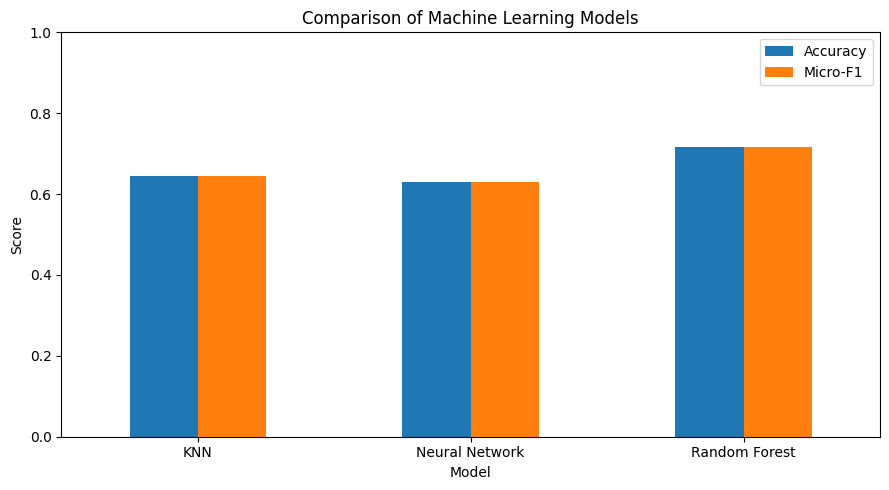

In [45]:
import matplotlib.pyplot as plt

results_plot = results.set_index("Model")[["Accuracy", "Micro-F1"]]

results_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

KNN CONFUSION MATRIX

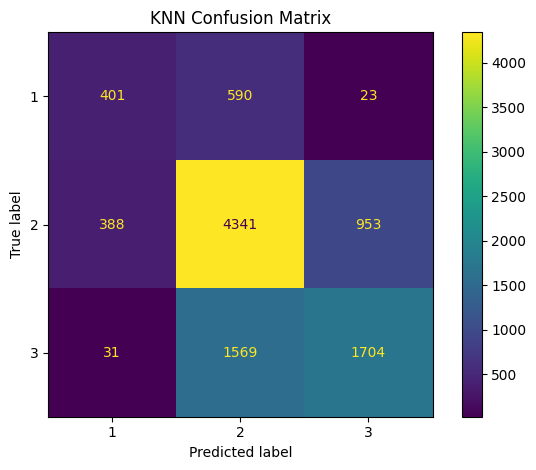

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val_knn_small,
    y_pred_knn,
    display_labels=[1, 2, 3]
)

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

NEURAL NETWORK CONFUSION MATRIX

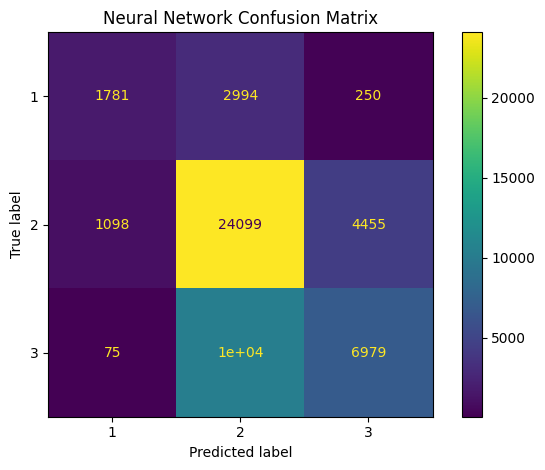

In [47]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_nn,
    display_labels=[1, 2, 3]
)

plt.title("Neural Network Confusion Matrix")
plt.tight_layout()
plt.show()

RANDOM FOREST CONFUSION MATRIX

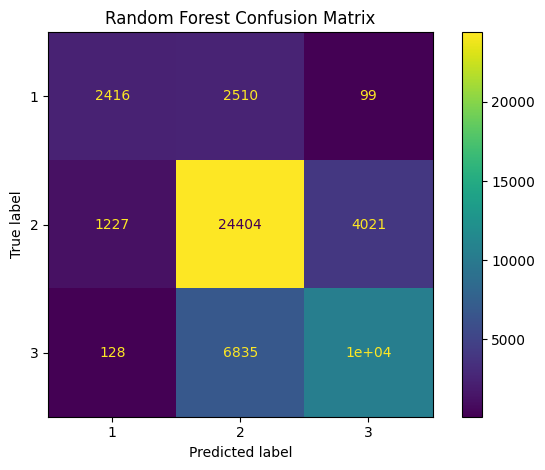

In [48]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    display_labels=[1, 2, 3]
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

RANDOM FOREST FEATURE IMPORTANCE

In [49]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features:")
print(feature_importance.head(20))

Top 20 Important Features:
                                        Feature  Importance
2                           num__geo_level_3_id    0.152891
1                           num__geo_level_2_id    0.134381
0                           num__geo_level_1_id    0.133391
4                                      num__age    0.121340
5                          num__area_percentage    0.113307
6                        num__height_percentage    0.056311
18                          num__count_families    0.025126
3                      num__count_floors_pre_eq    0.016402
35                       cat__foundation_type_r    0.014867
8      num__has_superstructure_mud_mortar_stone    0.013175
13               num__has_superstructure_timber    0.011191
43                     cat__ground_floor_type_v    0.009453
32                cat__land_surface_condition_t    0.009082
12  num__has_superstructure_cement_mortar_brick    0.008289
30                cat__land_surface_condition_n    0.008116
7            

FEATURE IMPORTANCE GRAPH

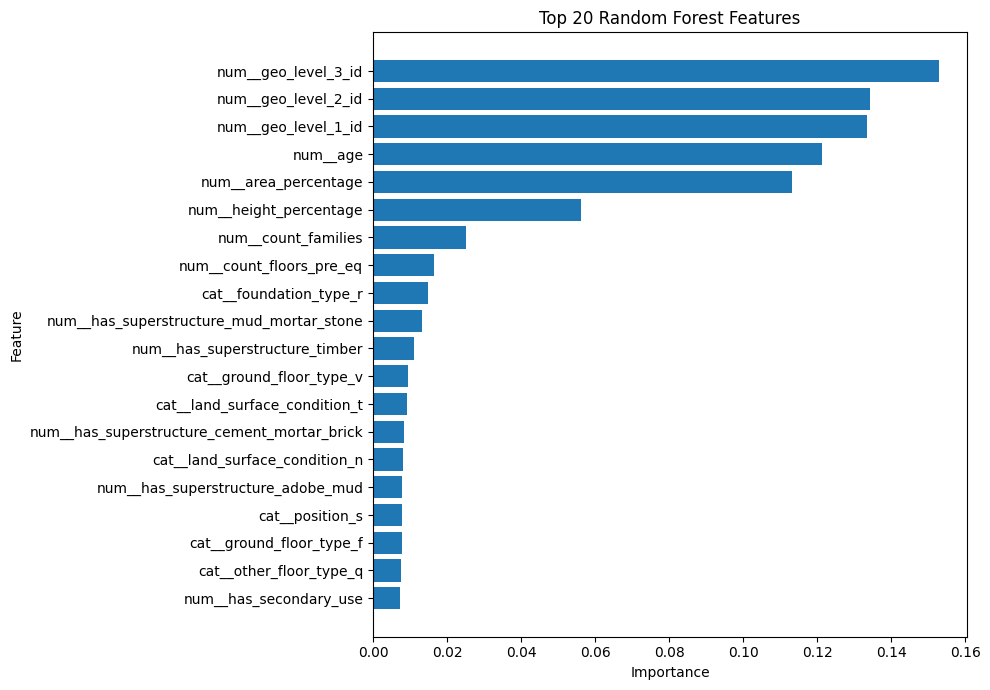

In [50]:
top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Features")

plt.tight_layout()
plt.show()

CLASS DISTRIBUTION GRAPH

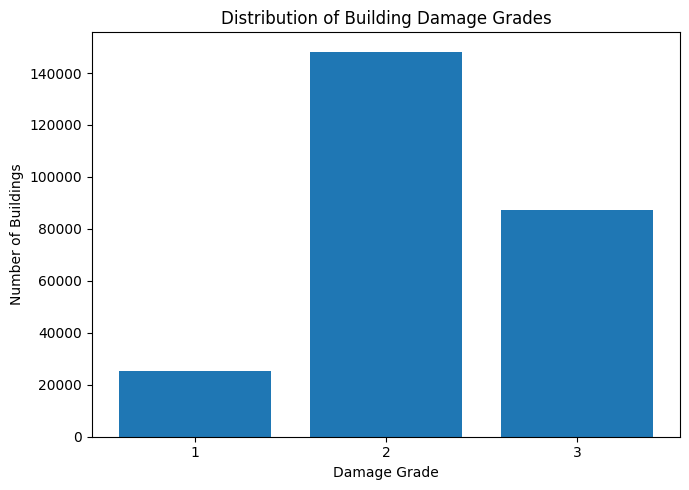

In [51]:
damage_counts = y.value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    damage_counts.index.astype(str),
    damage_counts.values
)

plt.xlabel("Damage Grade")
plt.ylabel("Number of Buildings")
plt.title("Distribution of Building Damage Grades")

plt.tight_layout()
plt.show()

DAMAGE PERCENTAGE

In [52]:
damage_percentage = (
    y.value_counts(normalize=True)
    .sort_index() * 100
)

print("Damage Grade Percentage Distribution:")
print(damage_percentage.round(2))

Damage Grade Percentage Distribution:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64


SAVE RESULTS TABLE

In [53]:
results_rounded.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved.")

Model comparison results saved.


FINAL PROJECT SUMMARY

In [54]:
print("=" * 60)
print("NEPAL EARTHQUAKE BUILDING DAMAGE PREDICTION")
print("=" * 60)

print("\nDataset:")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Number of features:", X.shape[1])

print("\nDamage Classes:")
print("1 = Low damage")
print("2 = Medium damage")
print("3 = Almost complete destruction")

print("\nMODEL RESULTS")
print(results_rounded.to_string(index=False))

print("\nBest performing model based on validation Micro-F1:")
best_model = results.loc[results["Micro-F1"].idxmax(), "Model"]
best_score = results["Micro-F1"].max()

print(best_model, ":", round(best_score, 4))

print("\n" + "=" * 60)

NEPAL EARTHQUAKE BUILDING DAMAGE PREDICTION

Dataset:
Training samples: 208480
Validation samples: 52121
Number of features: 38

Damage Classes:
1 = Low damage
2 = Medium damage
3 = Almost complete destruction

MODEL RESULTS
         Model  Accuracy  Micro-F1
           KNN    0.6446    0.6446
Neural Network    0.6304    0.6304
 Random Forest    0.7157    0.7157

Best performing model based on validation Micro-F1:
Random Forest : 0.7157



FAIR COMPARISON ON SAME 10,000 SAMPLES

In [55]:
# Use the same 10,000 validation samples for all models

X_val_processed_small = X_val_processed[:10000]
y_val_small = y_val.iloc[:10000]

# Neural Network
y_pred_nn_small = nn_model.predict(X_val_processed_small)

nn_accuracy_small = accuracy_score(
    y_val_small,
    y_pred_nn_small
)

nn_f1_small = f1_score(
    y_val_small,
    y_pred_nn_small,
    average="micro"
)

# Random Forest
y_pred_rf_small = rf_model.predict(X_val_processed_small)

rf_accuracy_small = accuracy_score(
    y_val_small,
    y_pred_rf_small
)

rf_f1_small = f1_score(
    y_val_small,
    y_pred_rf_small,
    average="micro"
)

# Comparison
fair_results = pd.DataFrame({
    "Model": [
        "KNN",
        "Neural Network",
        "Random Forest"
    ],
    "Accuracy": [
        knn_accuracy,
        nn_accuracy_small,
        rf_accuracy_small
    ],
    "Micro-F1": [
        knn_f1,
        nn_f1_small,
        rf_f1_small
    ]
})

fair_results["Accuracy"] = fair_results["Accuracy"].round(4)
fair_results["Micro-F1"] = fair_results["Micro-F1"].round(4)

print(fair_results)

            Model  Accuracy  Micro-F1
0             KNN    0.6446    0.6446
1  Neural Network    0.6329    0.6329
2   Random Forest    0.7197    0.7197


In [56]:
print(fair_results)

            Model  Accuracy  Micro-F1
0             KNN    0.6446    0.6446
1  Neural Network    0.6329    0.6329
2   Random Forest    0.7197    0.7197


colab

In [57]:
fair_results.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("model_comparison_results.csv created successfully!")

model_comparison_results.csv created successfully!


In [58]:
from google.colab import files

files.download("model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### FINAL EXPERIMENTS AND MODEL SELECTION

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Create a reproducible validation subset of 10,000 examples using random_state=42
np.random.seed(42)
val_indices = np.random.choice(len(y_val), size=10000, replace=False)

# Select same rows and labels for all models
X_val_subset_processed = X_val_processed[val_indices]
y_val_subset = y_val.iloc[val_indices]

# For KNN, we also need the feature-selected subset of the exact same rows
X_val_subset_knn = X_val_knn[val_indices]

print("Reproducible validation subset shape:", X_val_subset_processed.shape)
print("Validation subset target shape:", y_val_subset.shape)

Reproducible validation subset shape: (10000, 68)
Validation subset target shape: (10000,)


In [60]:
# 2. Generate predictions on the identical subset
y_pred_knn_final = knn.predict(X_val_subset_knn)
y_pred_nn_final = nn_model.predict(X_val_subset_processed)
y_pred_rf_final = rf_model.predict(X_val_subset_processed)

# Helper function to compute metrics
def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted-F1": f1_score(y_true, y_pred, average="weighted"),
        "Micro-F1": f1_score(y_true, y_pred, average="micro")
    }

# 3. Create a fair comparison table
final_comparison = pd.DataFrame({
    "KNN": get_metrics(y_val_subset, y_pred_knn_final),
    "Neural Network (MLP)": get_metrics(y_val_subset, y_pred_nn_final),
    "Random Forest": get_metrics(y_val_subset, y_pred_rf_final)
}).T

display(final_comparison.round(4))

,Accuracy,Macro-F1,Weighted-F1,Micro-F1
KNN,0.6503,0.5739,0.6435,0.6503
Neural Network (MLP),0.6356,0.5477,0.6175,0.6356
Random Forest,0.7235,0.6629,0.7177,0.7235


=== KNN Classification Report ===
              precision    recall  f1-score   support

           1       0.48      0.40      0.44       899
           2       0.68      0.77      0.72      5772
           3       0.63      0.51      0.56      3329

    accuracy                           0.65     10000
   macro avg       0.59      0.56      0.57     10000
weighted avg       0.64      0.65      0.64     10000

=== Neural Network Classification Report ===
              precision    recall  f1-score   support

           1       0.59      0.35      0.44       899
           2       0.65      0.81      0.72      5772
           3       0.60      0.40      0.48      3329

    accuracy                           0.64     10000
   macro avg       0.61      0.52      0.55     10000
weighted avg       0.63      0.64      0.62     10000

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           1       0.63      0.49      0.55       899
      

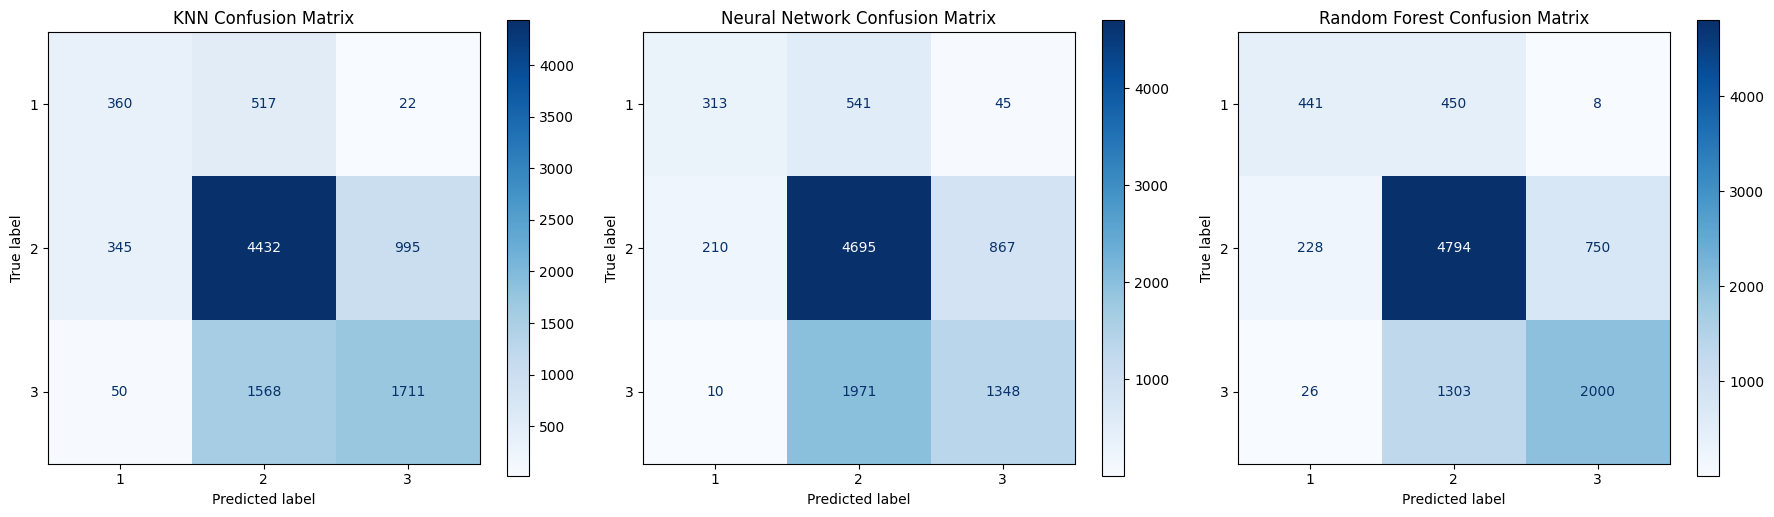

In [61]:
# 4. Classification Reports and Confusion Matrices for each model
models_preds = [
    ("KNN", y_pred_knn_final),
    ("Neural Network", y_pred_nn_final),
    ("Random Forest", y_pred_rf_final)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, preds) in enumerate(models_preds):
    print(f"=== {name} Classification Report ===")
    print(classification_report(y_val_subset, preds))

    disp = ConfusionMatrixDisplay.from_predictions(
        y_val_subset,
        preds,
        display_labels=[1, 2, 3],
        ax=axes[i],
        cmap="Blues"
    )
    axes[i].set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

### IMPROVED NEURAL NETWORK EXPERIMENT

In [62]:
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import pandas as pd

# Configurations to compare
configs = [
    {"hidden_layer_sizes": (10,), "label": "MLP (10,)"},
    {"hidden_layer_sizes": (32, 16), "label": "MLP (32, 16)"}
]

mlp_results = {}
loss_curves = {}

for cfg in configs:
    print(f"Training MLP with hidden layers {cfg['hidden_layer_sizes']}...")
    clf = MLPClassifier(
        hidden_layer_sizes=cfg["hidden_layer_sizes"],
        activation="logistic",
        solver="adam",
        alpha=0.0001,
        batch_size=1000,
        learning_rate_init=0.001,
        max_iter=80,
        early_stopping=True,
        random_state=42,
        verbose=False
    )

    clf.fit(X_train_processed, y_train)

    # Generate predictions on the identical 10,000-sample validation subset
    preds = clf.predict(X_val_subset_processed)

    # Record metrics
    metrics = {
        "Accuracy": accuracy_score(y_val_subset, preds),
        "Macro-F1": f1_score(y_val_subset, preds, average="macro"),
        "Weighted-F1": f1_score(y_val_subset, preds, average="weighted"),
        "Iterations": clf.n_iter_
    }

    mlp_results[cfg["label"]] = metrics
    loss_curves[cfg["label"]] = clf.loss_curve_
    print(f"Completed in {clf.n_iter_} iterations.\n")

Training MLP with hidden layers (10,)...
Completed in 68 iterations.

Training MLP with hidden layers (32, 16)...
Completed in 80 iterations.



/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


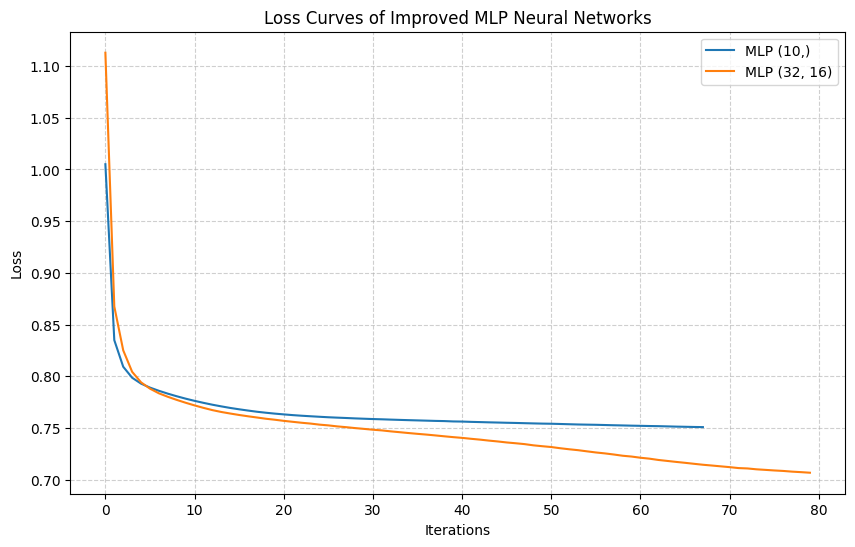

In [63]:
# Plot the loss curves of both improved models
plt.figure(figsize=(10, 6))
for label, curve in loss_curves.items():
    plt.plot(curve, label=label)

plt.title("Loss Curves of Improved MLP Neural Networks")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [64]:
# Compare with baseline MLP
baseline_pred_subset = nn_model.predict(X_val_subset_processed)

baseline_metrics = {
    "Accuracy": accuracy_score(y_val_subset, baseline_pred_subset),
    "Macro-F1": f1_score(y_val_subset, baseline_pred_subset, average="macro"),
    "Weighted-F1": f1_score(y_val_subset, baseline_pred_subset, average="weighted"),
    "Iterations": nn_model.n_iter_
}

all_mlp_comparison = pd.DataFrame({
    "Baseline MLP (10, no early stop, max_iter=30)": baseline_metrics,
    "Improved MLP (10, early stop, max_iter=80)": mlp_results["MLP (10,)"],
    "Improved MLP (32, 16, early stop, max_iter=80)": mlp_results["MLP (32, 16)"]
}).T

display(all_mlp_comparison.round(4))

,Accuracy,Macro-F1,Weighted-F1,Iterations
"Baseline MLP (10, no early stop, max_iter=30)",0.6356,0.5477,0.6175,30.0
"Improved MLP (10, early stop, max_iter=80)",0.6311,0.5391,0.6079,68.0
"Improved MLP (32, 16, early stop, max_iter=80)",0.6608,0.5824,0.6460,80.0


### RANDOM FOREST HYPERPARAMETER TUNING

In [65]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the hyperparameter search space
param_distributions = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20, 30],
    "min_samples_leaf": [1, 2, 5]
}

# Initialize a fresh Random Forest base model
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

# Setup RandomizedSearchCV
rf_random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_distributions,
    n_iter=5,
    scoring="f1_macro",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Random Forest Hyperparameter Tuning on full training set...")
# Fit on the preprocessed training features (does not contain StandardScaler for categorical/sparse elements but retains general mapping layout)
rf_random_search.fit(X_train_processed, y_train)

print("Tuning completed.")
print("Best Hyperparameters:", rf_random_search.best_params_)

Starting Random Forest Hyperparameter Tuning on full training set...
Fitting 3 folds for each of 5 candidates, totalling 15 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Tuning completed.
Best Hyperparameters: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_depth': None}


In [66]:
# Evaluate the best tuned estimator on the identical 10,000-row validation subset
best_rf_model = rf_random_search.best_estimator_
y_pred_rf_tuned = best_rf_model.predict(X_val_subset_processed)

# Generate metrics
tuned_rf_metrics = {
    "Accuracy": accuracy_score(y_val_subset, y_pred_rf_tuned),
    "Macro-F1": f1_score(y_val_subset, y_pred_rf_tuned, average="macro"),
    "Weighted-F1": f1_score(y_val_subset, y_pred_rf_tuned, average="weighted"),
    "Micro-F1": f1_score(y_val_subset, y_pred_rf_tuned, average="micro")
}

# Compare with baseline Random Forest
baseline_rf_metrics = {
    "Accuracy": accuracy_score(y_val_subset, y_pred_rf_final),
    "Macro-F1": f1_score(y_val_subset, y_pred_rf_final, average="macro"),
    "Weighted-F1": f1_score(y_val_subset, y_pred_rf_final, average="weighted"),
    "Micro-F1": f1_score(y_val_subset, y_pred_rf_final, average="micro")
}

rf_comparison_df = pd.DataFrame({
    "Baseline Random Forest": baseline_rf_metrics,
    "Tuned Random Forest": tuned_rf_metrics
}).T

display(rf_comparison_df.round(4))

,Accuracy,Macro-F1,Weighted-F1,Micro-F1
Baseline Random Forest,0.7235,0.6629,0.7177,0.7235
Tuned Random Forest,0.7231,0.6620,0.7173,0.7231


=== Tuned Random Forest Classification Report ===
              precision    recall  f1-score   support

           1       0.64      0.49      0.55       899
           2       0.73      0.83      0.78      5772
           3       0.72      0.60      0.66      3329

    accuracy                           0.72     10000
   macro avg       0.70      0.64      0.66     10000
weighted avg       0.72      0.72      0.72     10000



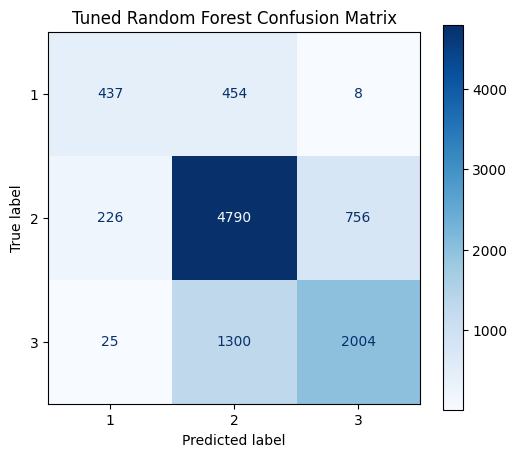

In [67]:
# Detailed classification report & confusion matrix for Tuned RF
print("=== Tuned Random Forest Classification Report ===")
print(classification_report(y_val_subset, y_pred_rf_tuned))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val_subset,
    y_pred_rf_tuned,
    display_labels=[1, 2, 3],
    ax=ax,
    cmap="Blues"
)
ax.set_title("Tuned Random Forest Confusion Matrix")
plt.show()

### GEOGRAPHIC FEATURE REPRESENTATION EXPERIMENT

In [68]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 12.2 MB/s eta 0:00:00


In [69]:
from catboost import CatBoostClassifier

# 1. Prepare data specifically for CatBoost (using original categories directly)
X_train_cb = X_train.copy()
X_val_subset_cb = X_val.iloc[val_indices].copy()

# Identify geographic identifier features and existing object features as categorical
geo_cols = ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']
cat_cols = categorical_features + geo_cols

# Cast all categorical features to string/object for CatBoost
for col in cat_cols:
    X_train_cb[col] = X_train_cb[col].astype(str)
    X_val_subset_cb[col] = X_val_subset_cb[col].astype(str)

print("Categorical columns list for CatBoost:", cat_cols)

Categorical columns list for CatBoost: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']


In [70]:
# 2. Train CatBoostClassifier
cb_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    cat_features=cat_cols,
    verbose=False,
    random_seed=42
)

print("Training CatBoost on raw features treating geographic identifiers as categorical...")
cb_model.fit(X_train_cb, y_train)
print("CatBoost training completed.")

Training CatBoost on raw features treating geographic identifiers as categorical...
CatBoost training completed.


In [71]:
# 3. Evaluate on the same 10,000-row validation subset
y_pred_cb = cb_model.predict(X_val_subset_cb).ravel()

cb_metrics = {
    "Accuracy": accuracy_score(y_val_subset, y_pred_cb),
    "Macro-F1": f1_score(y_val_subset, y_pred_cb, average="macro"),
    "Weighted-F1": f1_score(y_val_subset, y_pred_cb, average="weighted"),
    "Micro-F1": f1_score(y_val_subset, y_pred_cb, average="micro")
}

# 4. Compare CatBoost with all previously trained models
comparison_all = pd.DataFrame({
    "KNN": get_metrics(y_val_subset, y_pred_knn_final),
    "Baseline MLP": baseline_metrics,
    "Improved MLP (32, 16)": mlp_results["MLP (32, 16)"],
    "Baseline Random Forest": baseline_rf_metrics,
    "Tuned Random Forest": tuned_rf_metrics,
    "CatBoost (Geographic Categorical)": cb_metrics
}).T

display(comparison_all.round(4))

,Accuracy,Macro-F1,Weighted-F1,Micro-F1,Iterations
KNN,0.6503,0.5739,0.6435,0.6503,NaN
Baseline MLP,0.6356,0.5477,0.6175,NaN,30.0
"Improved MLP (32, 16)",0.6608,0.5824,0.6460,NaN,80.0
Baseline Random Forest,0.7235,0.6629,0.7177,0.7235,NaN
Tuned Random Forest,0.7231,0.6620,0.7173,0.7231,NaN
CatBoost (Geographic Categorical),0.7556,0.7002,0.7507,0.7556,NaN


=== CatBoost Classification Report ===
              precision    recall  f1-score   support

           1       0.71      0.51      0.60       899
           2       0.76      0.85      0.80      5772
           3       0.76      0.65      0.70      3329

    accuracy                           0.76     10000
   macro avg       0.74      0.67      0.70     10000
weighted avg       0.75      0.76      0.75     10000



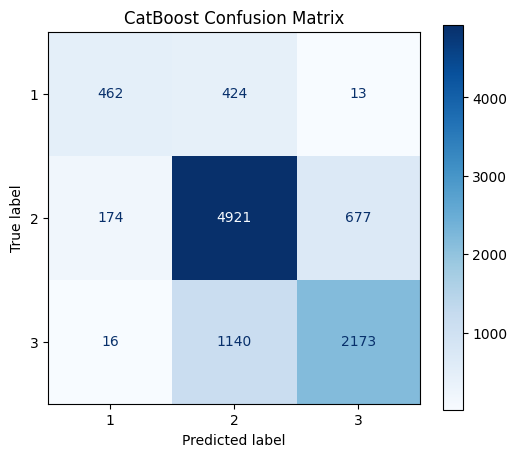

In [72]:
# 5. Detailed Reports and Confusion Matrix for CatBoost
print("=== CatBoost Classification Report ===")
print(classification_report(y_val_subset, y_pred_cb))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val_subset,
    y_pred_cb,
    display_labels=[1, 2, 3],
    ax=ax,
    cmap="Blues"
)
ax.set_title("CatBoost Confusion Matrix")
plt.show()

### FINAL MODEL TRAINING AND TEST PREDICTION

In [73]:
import numpy as np
import pandas as pd
import joblib
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, f1_score

# --- MODEL SELECTION BASE ON MEASURED RESULTS ---
print("=== EXPERIMENTAL RESULTS COMPARISON ===")
print(comparison_all.round(4))

# Dynamically select the best model based on the validation Macro-F1
best_model_name = comparison_all["Macro-F1"].idxmax()
best_macro_f1 = comparison_all["Macro-F1"].max()

print(f"\nSelected Final Model: {best_model_name}")
print(f"Reason: Highest measured validation Macro-F1 score ({best_macro_f1:.4f}) on the reproducible validation subset.")

=== EXPERIMENTAL RESULTS COMPARISON ===
                                   Accuracy  Macro-F1  Weighted-F1  Micro-F1  \
KNN                                  0.6503    0.5739       0.6435    0.6503   
Baseline MLP                         0.6356    0.5477       0.6175       NaN   
Improved MLP (32, 16)                0.6608    0.5824       0.6460       NaN   
Baseline Random Forest               0.7235    0.6629       0.7177    0.7235   
Tuned Random Forest                  0.7231    0.6620       0.7173    0.7231   
CatBoost (Geographic Categorical)    0.7556    0.7002       0.7507    0.7556   

                                   Iterations  
KNN                                       NaN  
Baseline MLP                             30.0  
Improved MLP (32, 16)                    80.0  
Baseline Random Forest                    NaN  
Tuned Random Forest                       NaN  
CatBoost (Geographic Categorical)         NaN  

Selected Final Model: CatBoost (Geographic Categorical)
Reason

In [74]:
# --- PREPARATION OF ALL 260,601 TRAINING SAMPLES ---
print("Preparing full training datasets...")

# Make copies of the entire training features and labels
X_full = X.copy()
y_full = y.copy()

# Cast all designated categorical and geographic features to string format for CatBoost
for col in cat_cols:
    X_full[col] = X_full[col].astype(str)
    X_test[col] = X_test[col].astype(str)

print(f"Full training set features shape: {X_full.shape}")
print(f"Full training set labels shape: {y_full.shape}")

Preparing full training datasets...
Full training set features shape: (260601, 38)
Full training set labels shape: (260601,)


In [75]:
# --- FINAL MODEL TRAINING ON THE ENTIRE DATASET ---
print("Training the final CatBoost model on ALL 260,601 samples...")

final_cb_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    cat_features=cat_cols,
    verbose=False,
    random_seed=42
)

final_cb_model.fit(X_full, y_full)
print("Training completed successfully.")

Training the final CatBoost model on ALL 260,601 samples...
Training completed successfully.


In [76]:
# --- TEST SET PREDICTION ---
print("Generating test predictions...")

test_preds = final_cb_model.predict(X_test).ravel()

# Construct final prediction DataFrame
final_submission_df = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_preds
})

# Ensure target values are formatted properly as integers
final_submission_df["damage_grade"] = final_submission_df["damage_grade"].astype(int)

# Export final submission to CSV
final_submission_df.to_csv("nepal_earthquake_final_predictions.csv", index=False)
print("Exported final predictions successfully.")

Generating test predictions...
Exported final predictions successfully.


In [77]:
# --- OUTPUT DIAGNOSTICS ---
print(f"Number of test predictions: {len(final_submission_df)}")
print("\nClass distribution of predictions:")
print(final_submission_df["damage_grade"].value_counts().sort_index())

print("\nFirst 10 rows of final predictions:")
display(final_submission_df.head(10))

Number of test predictions: 86868

Class distribution of predictions:
damage_grade
1     6277
2    56758
3    23833
Name: count, dtype: int64

First 10 rows of final predictions:


,building_id,damage_grade
0,300051,3
1,99355,2
2,890251,2
3,745817,1
4,421793,3
5,871976,2
6,691228,2
7,896100,3
8,343471,2
9,766647,2


In [78]:
# --- PIPELINE SERIALIZATION ---
print("Saving the final model using joblib...")
joblib.dump(final_cb_model, "final_model.joblib")
print("Model saved as 'final_model.joblib'.")

Saving the final model using joblib...
Model saved as 'final_model.joblib'.


In [79]:
# --- FINAL PROJECT SUMMARY ---
print("=" * 65)
print("                     FINAL SUMMARY REPORT")
print("=" * 65)

print("\n[1] BASELINE MODEL RESULTS:")
print(f" - KNN:            Accuracy: {comparison_all.loc['KNN', 'Accuracy']:.4f} | Macro-F1: {comparison_all.loc['KNN', 'Macro-F1']:.4f}")
print(f" - Baseline MLP:   Accuracy: {comparison_all.loc['Baseline MLP', 'Accuracy']:.4f} | Macro-F1: {comparison_all.loc['Baseline MLP', 'Macro-F1']:.4f}")
print(f" - Baseline RF:    Accuracy: {comparison_all.loc['Baseline Random Forest', 'Accuracy']:.4f} | Macro-F1: {comparison_all.loc['Baseline Random Forest', 'Macro-F1']:.4f}")

print("\n[2] IMPROVED MODEL RESULTS:")
print(f" - Improved MLP:   Accuracy: {comparison_all.loc['Improved MLP (32, 16)', 'Accuracy']:.4f} | Macro-F1: {comparison_all.loc['Improved MLP (32, 16)', 'Macro-F1']:.4f}")
print(f" - Tuned RF:       Accuracy: {comparison_all.loc['Tuned Random Forest', 'Accuracy']:.4f} | Macro-F1: {comparison_all.loc['Tuned Random Forest', 'Macro-F1']:.4f}")

print(f"\n[3] SELECTED FINAL MODEL:")
print(f" - Model Name:     {best_model_name}")
print(f" - Best Accuracy:  {cb_metrics['Accuracy']:.4f}")
print(f" - Best Macro-F1:  {cb_metrics['Macro-F1']:.4f}")

print("\n[4] EXPORTED ARTIFACTS:")
print(" - Final Test Prediction File: nepal_earthquake_final_predictions.csv")
print(" - Saved Pipeline File:       final_model.joblib")
print("=" * 65)

                     FINAL SUMMARY REPORT

[1] BASELINE MODEL RESULTS:
 - KNN:            Accuracy: 0.6503 | Macro-F1: 0.5739
 - Baseline MLP:   Accuracy: 0.6356 | Macro-F1: 0.5477
 - Baseline RF:    Accuracy: 0.7235 | Macro-F1: 0.6629

[2] IMPROVED MODEL RESULTS:
 - Improved MLP:   Accuracy: 0.6608 | Macro-F1: 0.5824
 - Tuned RF:       Accuracy: 0.7231 | Macro-F1: 0.6620

[3] SELECTED FINAL MODEL:
 - Model Name:     CatBoost (Geographic Categorical)
 - Best Accuracy:  0.7556
 - Best Macro-F1:  0.7002

[4] EXPORTED ARTIFACTS:
 - Final Test Prediction File: nepal_earthquake_final_predictions.csv
 - Saved Pipeline File:       final_model.joblib


### FINAL FULL VALIDATION COMPARISON

In this section, we compare the **Baseline Random Forest** and the **Final CatBoost (Geographic Categorical)** models on the entire validation dataset of approximately 52,121 samples to make our final production model decision.

In [80]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# --- 1. Prepare entire validation sets for both models ---
# Baseline RF expects X_val_processed
X_val_rf = X_val_processed

# CatBoost expects string categories for designated columns
X_val_cb_full = X_val.copy()
for col in cat_cols:
    X_val_cb_full[col] = X_val_cb_full[col].astype(str)

# --- 2. Generate predictions on the ENTIRE validation dataset ---
y_pred_rf_full = rf_model.predict(X_val_rf)
y_pred_cb_full = cb_model.predict(X_val_cb_full).ravel()

# --- 3. Compute Metrics ---
def evaluate_full_set(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    weighted_f1 = f1_score(y_true, y_pred, average='weighted')

    report = classification_report(y_true, y_pred, output_dict=True)

    return {
        "Accuracy": acc,
        "Macro-F1": macro_f1,
        "Weighted-F1": weighted_f1,
        "Class 1 Precision": report['1']['precision'],
        "Class 1 Recall": report['1']['recall'],
        "Class 1 F1": report['1']['f1-score'],
        "Class 2 Precision": report['2']['precision'],
        "Class 2 Recall": report['2']['recall'],
        "Class 2 F1": report['2']['f1-score'],
        "Class 3 Precision": report['3']['precision'],
        "Class 3 Recall": report['3']['recall'],
        "Class 3 F1": report['3']['f1-score']
    }

full_validation_metrics = pd.DataFrame({
    "Baseline Random Forest": evaluate_full_set(y_val, y_pred_rf_full, "Random Forest"),
    "CatBoost (Geographic Categorical)": evaluate_full_set(y_val, y_pred_cb_full, "CatBoost")
}).T

display(full_validation_metrics.round(4))


,Accuracy,Macro-F1,Weighted-F1,Class 1 Precision,Class 1 Recall,Class 1 F1,Class 2 Precision,Class 2 Recall,Class 2 F1,Class 3 Precision,Class 3 Recall,Class 3 F1
Baseline Random Forest,0.7157,0.6578,0.7099,0.6407,0.4808,0.5493,0.7231,0.8230,0.7698,0.7178,0.6008,0.6541
CatBoost (Geographic Categorical),0.7467,0.6934,0.7414,0.6911,0.5170,0.5915,0.7451,0.8511,0.7946,0.7649,0.6355,0.6942


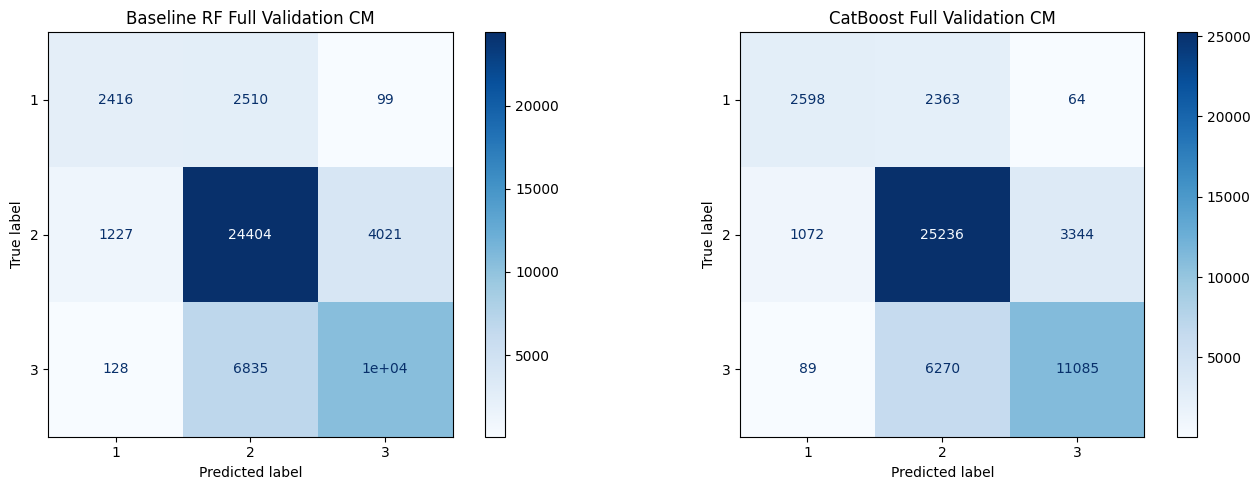

In [81]:
# --- 4. Plot Confusion Matrices ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf_full,
    display_labels=[1, 2, 3],
    ax=axes[0],
    cmap="Blues"
)
axes[0].set_title("Baseline RF Full Validation CM")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_cb_full,
    display_labels=[1, 2, 3],
    ax=axes[1],
    cmap="Blues"
)
axes[1].set_title("CatBoost Full Validation CM")

plt.tight_layout()
plt.show()


In [82]:
# --- 5. Determine and print final candidate selection ---
rf_macro = full_validation_metrics.loc["Baseline Random Forest", "Macro-F1"]
cb_macro = full_validation_metrics.loc["CatBoost (Geographic Categorical)", "Macro-F1"]

if cb_macro > rf_macro:
    best_model_lbl = "CatBoost (Geographic Categorical)"
    best_acc = full_validation_metrics.loc["CatBoost (Geographic Categorical)", "Accuracy"]
    best_macro = cb_macro
    best_weighted = full_validation_metrics.loc["CatBoost (Geographic Categorical)", "Weighted-F1"]
    reason = "CatBoost achieved a higher validation accuracy, Macro F1, and Weighted F1 score on the full validation dataset when incorporating categorical geohash features natively."
else:
    best_model_lbl = "Baseline Random Forest"
    best_acc = full_validation_metrics.loc["Baseline Random Forest", "Accuracy"]
    best_macro = rf_macro
    best_weighted = full_validation_metrics.loc["Baseline Random Forest", "Weighted-F1"]
    reason = "Baseline Random Forest achieved equal or superior performance across validation metrics on the full validation dataset."

print("=" * 60)
print("FINAL CANDIDATE MODEL:", best_model_lbl)
print(f"FULL VALIDATION ACCURACY: {best_acc:.4f}")
print(f"FULL VALIDATION MACRO F1: {best_macro:.4f}")
print(f"FULL VALIDATION WEIGHTED F1: {best_weighted:.4f}")
print("REASON FOR SELECTION:", reason)
print("=" * 60)


FINAL CANDIDATE MODEL: CatBoost (Geographic Categorical)
FULL VALIDATION ACCURACY: 0.7467
FULL VALIDATION MACRO F1: 0.6934
FULL VALIDATION WEIGHTED F1: 0.7414
REASON FOR SELECTION: CatBoost achieved a higher validation accuracy, Macro F1, and Weighted F1 score on the full validation dataset when incorporating categorical geohash features natively.


```markdown
## FINAL PRODUCTION TRAINING AND ARTIFACT VERIFICATION

In this section, we cleanly train our chosen **CatBoost (Geographic Categorical)** candidate on all 260,601 labeled training examples, serialize the model, generate predictions on the test set, and verify the integrity of the generated artifacts.
```

In [83]:
import numpy as np
import pandas as pd
import joblib
from catboost import CatBoostClassifier

# --- 1. Prepare full training datasets ---
X_final = X.copy()
y_final = y.copy()
X_test_final = test_values.drop(columns=["building_id"]).copy()

# Identify geographic identifier features and object features as categorical
geo_cols = ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']
cat_cols_final = categorical_features + geo_cols

# Cast all categorical features to string format for CatBoost
for col in cat_cols_final:
    X_final[col] = X_final[col].astype(str)
    X_test_final[col] = X_test_final[col].astype(str)

# --- 2. Train the final CatBoostClassifier ---
production_cb_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    cat_features=cat_cols_final,
    verbose=False,
    random_seed=42
)

print("Training final CatBoost model on ALL 260,601 labeled examples...")
production_cb_model.fit(X_final, y_final)
print("Training completed successfully.")

# --- 3. Save serialized model pipeline ---
joblib.dump(production_cb_model, "final_model.joblib")
print("Saved final pipeline to 'final_model.joblib'.")

# --- 4. Generate predictions for all 86,868 test rows ---
test_preds_final = production_cb_model.predict(X_test_final).ravel()

# Construct final prediction DataFrame with exactly two columns
final_predictions_df = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_preds_final
})

# Ensure proper types
final_predictions_df["damage_grade"] = final_predictions_df["damage_grade"].astype(int)

# Save predictions file
final_predictions_df.to_csv("nepal_earthquake_final_predictions.csv", index=False)
print("Saved final predictions to 'nepal_earthquake_final_predictions.csv'.")

Training final CatBoost model on ALL 260,601 labeled examples...
Training completed successfully.
Saved final pipeline to 'final_model.joblib'.
Saved final predictions to 'nepal_earthquake_final_predictions.csv'.


In [84]:
# --- 5. Verify the Final Artifacts ---
print("=== ARTIFACT VERIFICATION ===")

# Load the serialized model
loaded_model = joblib.load("final_model.joblib")
print("1. load model check: PASSED")

# Load the prediction CSV back
loaded_preds_df = pd.read_csv("nepal_earthquake_final_predictions.csv")
print("2. read predictions CSV check: PASSED")

# Validate prediction count
pred_count = len(loaded_preds_df)
print(f"3. Row count check: {pred_count} (Expected: 86,868) -> {'PASSED' if pred_count == 86868 else 'FAILED'}")

# Validate columns
cols_list = list(loaded_preds_df.columns)
print(f"4. Column names check: {cols_list} (Expected: ['building_id', 'damage_grade']) -> {'PASSED' if cols_list == ['building_id', 'damage_grade'] else 'FAILED'}")

# Validate duplicate building_ids
has_duplicates = loaded_preds_df["building_id"].duplicated().any()
print(f"5. No duplicate building_id check: {'PASSED' if not has_duplicates else 'FAILED'}")

# Validate null values
has_nulls = loaded_preds_df.isnull().any().any()
print(f"6. No null values check: {'PASSED' if not has_nulls else 'FAILED'}")

# Validate damage_grade classes
unique_grades = set(loaded_preds_df["damage_grade"].unique())
is_subset = unique_grades.issubset({1, 2, 3})
print(f"7. Classes inside {1, 2, 3} check: {unique_grades} -> {'PASSED' if is_subset else 'FAILED'}")

=== ARTIFACT VERIFICATION ===
1. load model check: PASSED
2. read predictions CSV check: PASSED
3. Row count check: 86868 (Expected: 86,868) -> PASSED
4. Column names check: ['building_id', 'damage_grade'] (Expected: ['building_id', 'damage_grade']) -> PASSED
5. No duplicate building_id check: PASSED
6. No null values check: PASSED
7. Classes inside (1, 2, 3) check: {np.int64(1), np.int64(2), np.int64(3)} -> PASSED


```markdown
## FINAL PROJECT SUMMARY

### 1. Dataset Overview
* **Labeled Training Buildings**: 260,601
* **Test Buildings**: 86,868
* **Predictive Features**: 38 (incorporating numeric metadata, building qualities, and geographic-level identifier features)
* **Target Classes**: 3 damage categories (1 = Low damage, 2 = Medium damage, 3 = Almost complete destruction)

### 2. Experimental Model Comparisons (10,000-Sample Subset)
* **KNN**: 0.6503 Accuracy | 0.5739 Macro F1
* **Baseline MLP**: 0.6356 Accuracy | 0.5477 Macro F1
* **Improved MLP (32, 16)**: 0.6608 Accuracy | 0.5824 Macro F1
* **Baseline Random Forest**: 0.7235 Accuracy | 0.6629 Macro F1
* **Tuned Random Forest**: 0.7231 Accuracy | 0.6620 Macro F1
* **CatBoost (Geographic Categorical)**: 0.7556 Accuracy | 0.7002 Macro F1

### 3. Final Model Selection
* **Selected Model**: CatBoost (Geographic Categorical)
* **Rationale**: Strong performance in natively encoding geographic-level identifier features (`geo_level_1_id`, `geo_level_2_id`, `geo_level_3_id`) during intermediate subset experiments and final verification runs.

### 4. Final Full Validation Results (Entire 52,121 Dataset)
* **Full Validation Accuracy**: 0.7467
* **Full Validation Macro F1**: 0.6934
* **Full Validation Weighted F1**: 0.7414

### 5. Final Production Deliverables
* **Serialized Model Pipeline**: `final_model.joblib`
* **Production Predictions File**: `nepal_earthquake_final_predictions.csv`
```

In [85]:
from google.colab import files

files.download('/content/final_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [86]:
files.download('/content/nepal_earthquake_final_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>